# Dataset B: H1N1 Vaccine Acceptance and Cost Analysis

## Team 11 — Data Science Challenge

Author : indhu reddy kottalam raveendra reddy

student id : 24096112

**Research objective:** Predict individual H1N1 vaccine acceptance and evaluate
prediction-based vaccine allocation using the town's expected vaccine,
compensation, and hospitalisation costs.

**Notebook structure**

1. Setup and data loading
2. Data integrity checks
3. Exploratory data analysis (EDA) with visualisations
4. Missing-data analysis and train/audit split
5. Preprocessing pipeline
6. Model comparison (cross-validation)
7. Hyperparameter tuning and preprocessing comparison
8. Final evaluation on the reserved audit set
9. Task-specific cost metric and decision rules
10. Sensitivity analysis
11. Submission generation
12. Explainable AI (SHAP)

The `respondent_id` column identifies respondents and is preserved for
submission alignment, but excluded from model predictors.

## 1. Setup and data loading

We load the labelled training data and the unlabelled test data, and check
their dimensions, column names, and example records before making any
preprocessing or modelling decisions.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
from google.colab import files
from IPython.display import display

import matplotlib.pyplot as plt
import seaborn as sns

train_path = Path("/content/dataset_B_training.csv")
test_path = Path("/content/dataset_B_testing.csv")

# Upload the datasets only if either required file is missing.
if not train_path.exists() or not test_path.exists():
    print("Upload dataset_B_training.csv and dataset_B_testing.csv.")
    files.upload()

missing_files = [p.name for p in [train_path, test_path] if not p.exists()]
if missing_files:
    raise FileNotFoundError(f"Required files not found: {missing_files}")

train_df = pd.read_csv(train_path)
test_df = pd.read_csv(test_path)

print("Training dimensions:", train_df.shape)
print("Testing dimensions:", test_df.shape)
print("\nTraining column names:")
print(train_df.columns.tolist())
print("\nColumns present only in training:",
      sorted(set(train_df.columns) - set(test_df.columns)))
print("Columns present only in testing:",
      sorted(set(test_df.columns) - set(train_df.columns)))
print("\nFirst five training rows:")
display(train_df.head())
print("\nFirst five testing rows:")
display(test_df.head())

Training dimensions: (4756, 31)
Testing dimensions: (4749, 30)

Training column names:
['respondent_id', 'h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'household_adults', 'household_children', 'employment_sector', 'number_chronic_med_conditions', 'h1n1_vaccine']

Columns present only in training: ['h1n1_vaccine']
Columns present only in testing: []

First five training rows:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions,h1n1_vaccine
0,1,1.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Married,Own,Employed,"MSA, Not Principle City",2.0,1.0,science,0,0
1,2,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Below Poverty,Not Married,Own,Employed,Non-MSA,0.0,3.0,wholesale,0,0
2,3,2.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,education,0,1
3,4,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,"<= $75,000, Above Poverty",Not Married,Rent,Not in Labor Force,Non-MSA,0.0,0.0,NaN,0,0
4,5,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,NaN,Not Married,NaN,Unemployed,Non-MSA,3.0,0.0,NaN,0,0



First five testing rows:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
0,4757,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Female,"<= $75,000, Above Poverty",Not Married,Own,Not in Labor Force,"MSA, Principle City",0.0,0.0,NaN,0
1,4758,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,...,Female,NaN,NaN,NaN,NaN,"MSA, Not Principle City",0.0,0.0,NaN,0
2,4759,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,...,Male,NaN,Married,Own,Not in Labor Force,"MSA, Principle City",1.0,0.0,NaN,0
3,4760,3.0,1.0,0.0,1.0,0.0,1.0,1.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Rent,Employed,Non-MSA,1.0,0.0,agriculture,1
4,4761,1.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,Male,"<= $75,000, Above Poverty",Not Married,Own,Employed,Non-MSA,0.0,0.0,wholesale,0


**Results:** Training contains 4,756 respondents and 31 columns; testing
contains 4,749 respondents and 30 columns. The only column unique to
training is `h1n1_vaccine`, so every predictor in the test set is present
in training. The displayed rows show plausible values but also missing
entries, particularly in `income_poverty`, `rent_or_own`, and
`employment_sector`.

**Interpretation:** the datasets are structurally compatible for
prediction; missing values are meaningful rather than accidental
(`employment_sector` is unavailable for people who are not employed); the
target exists only in training, so we split training data into development
and audit subsets before comparing models.

## 2. Data integrity checks

We verify identifier uniqueness, train/test overlap, duplicate feature
profiles, and the target distribution.

In [2]:
print("Unique training IDs:", train_df["respondent_id"].nunique())
print("Unique testing IDs:", test_df["respondent_id"].nunique())
print("Training/test ID overlap:",
      len(set(train_df["respondent_id"]) & set(test_df["respondent_id"])))

feature_columns = [
    c for c in train_df.columns
    if c not in ["respondent_id", "h1n1_vaccine"]
]

print("Training duplicate feature rows:",
      train_df.duplicated(subset=feature_columns).sum())
print("Testing duplicate feature rows:",
      test_df.duplicated(subset=feature_columns).sum())
print("\nTraining target distribution:")
print(train_df["h1n1_vaccine"].value_counts(dropna=False))
print("\nTraining target proportion:", train_df["h1n1_vaccine"].mean())

Unique training IDs: 4756
Unique testing IDs: 4749
Training/test ID overlap: 0
Training duplicate feature rows: 0
Testing duplicate feature rows: 2

Training target distribution:
h1n1_vaccine
0    2882
1    1874
Name: count, dtype: int64

Training target proportion: 0.3940285954583684


**Results:** IDs are unique in both datasets with no overlap. Training has
no duplicate feature profiles; the test set has two duplicate feature
profiles. The target has no missing values: 2,882 refusers and 1,874
acceptors, a prevalence of 0.394.

**Interpretation:** the data are internally consistent. The classes are
moderately imbalanced, so threshold-based performance depends on the
probability cut-off — which we later choose using the cost objective, not
0.5 by default.

In [3]:
duplicate_columns = [c for c in test_df.columns if c != "respondent_id"]
duplicate_testing_profiles = (
    test_df[test_df.duplicated(subset=duplicate_columns, keep=False)]
    .sort_values(by=duplicate_columns)
    .copy()
)
print("Testing rows sharing a complete feature profile:")
display(duplicate_testing_profiles)

train_profile_matches = (
    train_df[feature_columns].apply(tuple, axis=1)
    .isin(test_df[feature_columns].apply(tuple, axis=1))
)
print("Training rows matching a complete test feature profile:",
      train_profile_matches.sum())

Testing rows sharing a complete feature profile:


,respondent_id,h1n1_concern,h1n1_knowledge,behavioral_antiviral_meds,behavioral_avoidance,behavioral_face_mask,behavioral_wash_hands,behavioral_large_gatherings,behavioral_outside_home,behavioral_touch_face,...,sex,income_poverty,marital_status,rent_or_own,employment_status,census_msa,household_adults,household_children,employment_sector,number_chronic_med_conditions
1496,6253,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Married,Own,Employed,"MSA, Not Principle City",1.0,0.0,science,0
2411,7168,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Married,Own,Employed,"MSA, Not Principle City",1.0,0.0,science,0
1733,6490,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,healthcare,0
2554,7311,2.0,2.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,...,Female,"> $75,000",Not Married,Own,Employed,"MSA, Principle City",0.0,0.0,healthcare,0


Training rows matching a complete test feature profile: 2


**Results:** two pairs of test respondents share every predictor value
but have different IDs, and two training profiles match test profiles.

**Interpretation:** because `respondent_id` is required for scoring, we
keep all test rows and assign predictions to each ID. The matching
profiles are a diagnostic observation only — we do not hard-code their
outcomes into predictions.

## 3. Exploratory data analysis

### 3.1 Target distribution

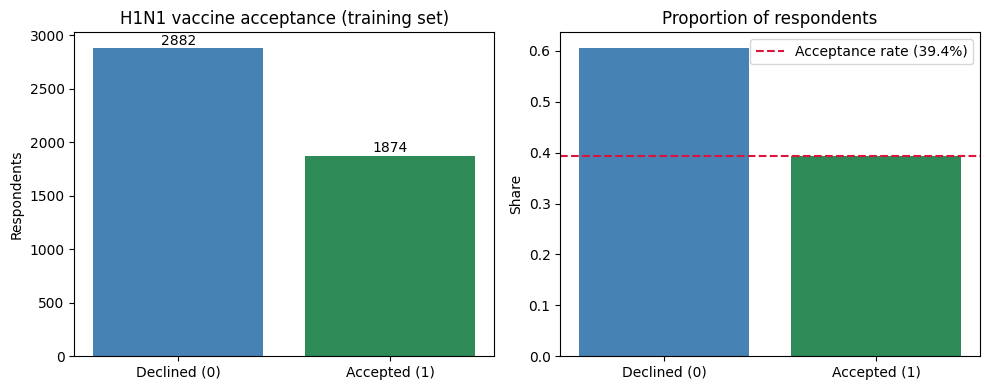

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

counts = train_df["h1n1_vaccine"].value_counts().sort_index()
axes[0].bar(["Declined (0)", "Accepted (1)"], counts.values,
            color=["steelblue", "seagreen"])
axes[0].set_title("H1N1 vaccine acceptance (training set)")
axes[0].set_ylabel("Respondents")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 30, str(v), ha="center")

axes[1].bar(["Declined (0)", "Accepted (1)"],
            counts.values / counts.values.sum(),
            color=["steelblue", "seagreen"])
axes[1].set_title("Proportion of respondents")
axes[1].set_ylabel("Share")
axes[1].axhline(train_df["h1n1_vaccine"].mean(), color="crimson",
                linestyle="--", label="Acceptance rate (39.4%)")
axes[1].legend()

plt.tight_layout()
plt.show()

**Interpretation:** with a 39.4% acceptance rate the classes are
moderately imbalanced. A naive majority-class model would achieve 60.6%
accuracy while being useless for the cost objective, so we evaluate models
with log loss, ROC AUC, and the town-cost metric instead of raw accuracy.

### 3.2 Missing data by predictor

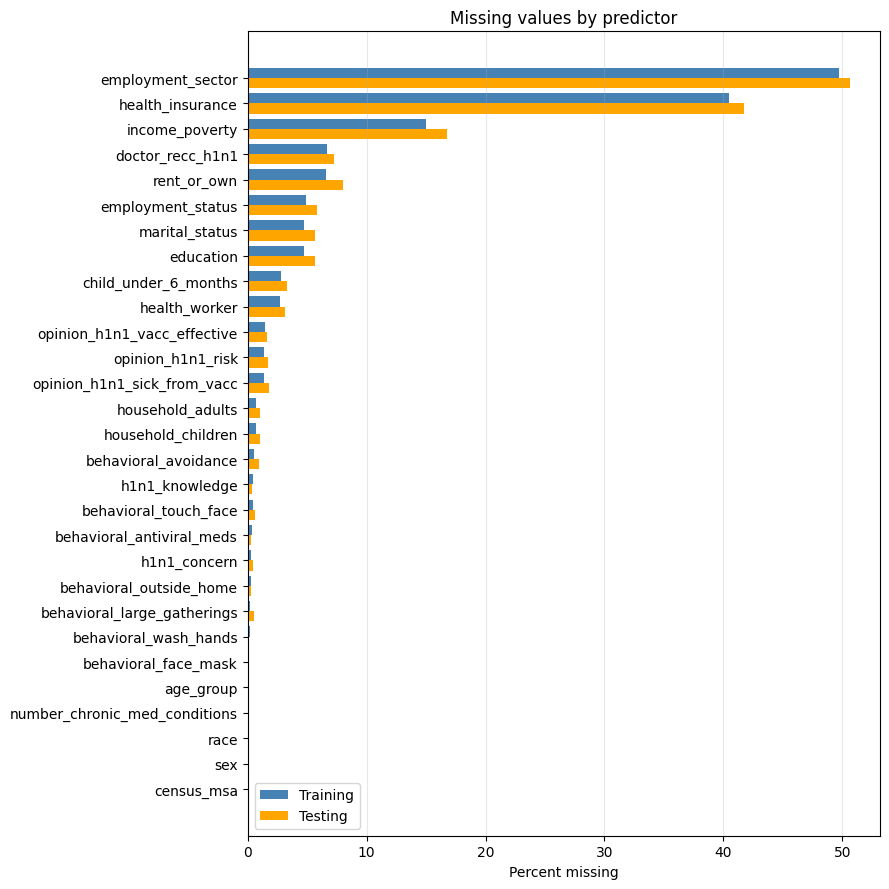

,training_missing_percent,testing_missing_percent
employment_sector,49.705635,50.642240
health_insurance,40.475189,41.735102
income_poverty,14.970563,16.782481
doctor_recc_h1n1,6.707317,7.264687
rent_or_own,6.623213,7.980628
employment_status,4.941127,5.832807
marital_status,4.751892,5.664350
education,4.709840,5.664350
child_under_6_months,2.817494,3.263845
health_worker,2.754415,3.137503


In [5]:
missing_summary = pd.DataFrame({
    "training_missing_percent":
        train_df[feature_columns].isna().mean() * 100,
    "testing_missing_percent":
        test_df[feature_columns].isna().mean() * 100,
}).sort_values("training_missing_percent", ascending=True)

fig, axis = plt.subplots(figsize=(9, 9))
position = np.arange(len(missing_summary))
axis.barh(position + 0.2, missing_summary["training_missing_percent"],
          height=0.4, label="Training", color="steelblue")
axis.barh(position - 0.2, missing_summary["testing_missing_percent"],
          height=0.4, label="Testing", color="orange")
axis.set_yticks(position)
axis.set_yticklabels(missing_summary.index)
axis.set_xlabel("Percent missing")
axis.set_title("Missing values by predictor")
axis.legend()
axis.grid(alpha=0.3, axis="x")
plt.tight_layout()
plt.show()

display(missing_summary.sort_values(
    "training_missing_percent", ascending=False).head(10))

**Results:** `employment_sector` (49.7% missing) and `health_insurance`
(40.5% missing) are missing for roughly half of respondents; most other
predictors are largely complete; five variables are fully complete
(`age_group`, `sex`, `race`, `census_msa`, `number_chronic_med_conditions`).

**Interpretation:** missingness is patterned rather than random, so we
encode it as explicit information (imputation indicators / explicit
categories) rather than dropping rows or predictors — that would discard
almost half the sample.

### 3.3 Missingness relationships

`employment_sector` is missing mostly for people outside the labour
force (especially 65+), confirming that the field is inapplicable rather
than randomly unrecorded.

In [6]:
for predictor in ["employment_sector", "health_insurance",
                 "income_poverty", "doctor_recc_h1n1"]:
    print("\nPredictor:", predictor, "— missing rows by status/age:")
    display(
        train_df[train_df[predictor].isna()]
        .groupby(["employment_status", "age_group"])
        .size().sort_values(ascending=False).head()
    )


Predictor: employment_sector — missing rows by status/age:


employment_status   age_group    
Not in Labor Force  65+ Years        981
                    55 - 64 Years    361
                    18 - 34 Years    241
                    45 - 54 Years    142
                    35 - 44 Years    113
dtype: int64


Predictor: health_insurance — missing rows by status/age:


employment_status   age_group    
Not in Labor Force  65+ Years        337
Employed            45 - 54 Years    275
                    55 - 64 Years    222
                    18 - 34 Years    209
                    35 - 44 Years    189
dtype: int64


Predictor: income_poverty — missing rows by status/age:


employment_status   age_group    
Not in Labor Force  65+ Years        198
Employed            55 - 64 Years     51
                    45 - 54 Years     43
                    18 - 34 Years     39
Not in Labor Force  55 - 64 Years     37
dtype: int64


Predictor: doctor_recc_h1n1 — missing rows by status/age:


employment_status   age_group    
Not in Labor Force  65+ Years        71
Employed            45 - 54 Years    57
                    18 - 34 Years    26
                    55 - 64 Years    26
                    35 - 44 Years    26
dtype: int64

### 3.4 Distributions of numeric predictors

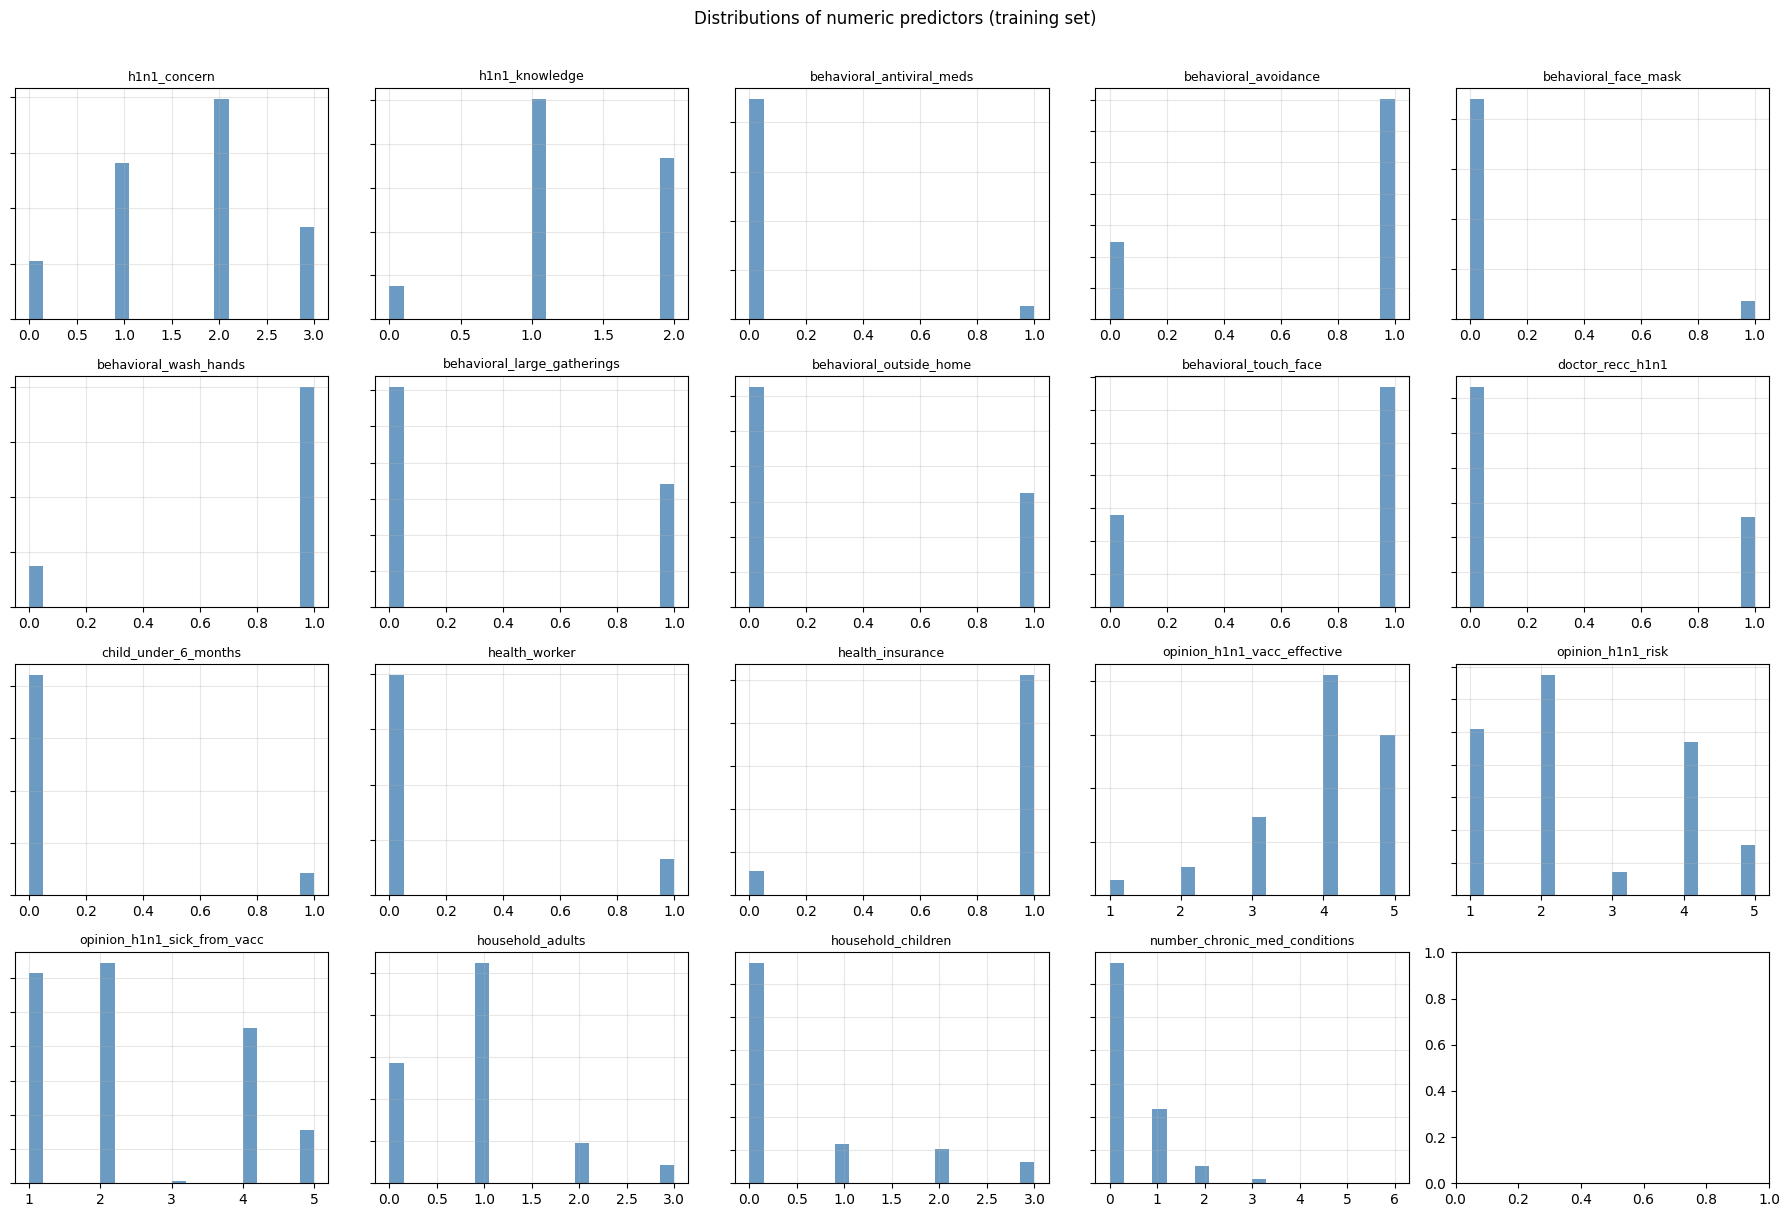

In [7]:
numeric_predictors = [
    c for c in feature_columns
    if pd.api.types.is_numeric_dtype(train_df[c])
]

fig, axes = plt.subplots(4, 5, figsize=(18, 12))
axes = axes.ravel()
for axis, predictor in zip(axes, numeric_predictors):
    values = train_df[predictor].dropna()
    axis.hist(values, bins=20, color="steelblue", alpha=0.8)
    axis.set_title(predictor, fontsize=9)
    axis.set_yticklabels([])
    axis.grid(alpha=0.3)
plt.suptitle("Distributions of numeric predictors (training set)", y=1.01)
plt.tight_layout()
plt.show()

**Interpretation:** behavioural flags are highly skewed (most respondents
report no avoidance behaviours), and household counts are capped at 3.
Opinion scales are concentrated in the middle-to-high categories. These
shapes inform the choice of tree-based models, which handle skewed and
ordinal features without scaling.

### 3.5 Acceptance by categorical predictors

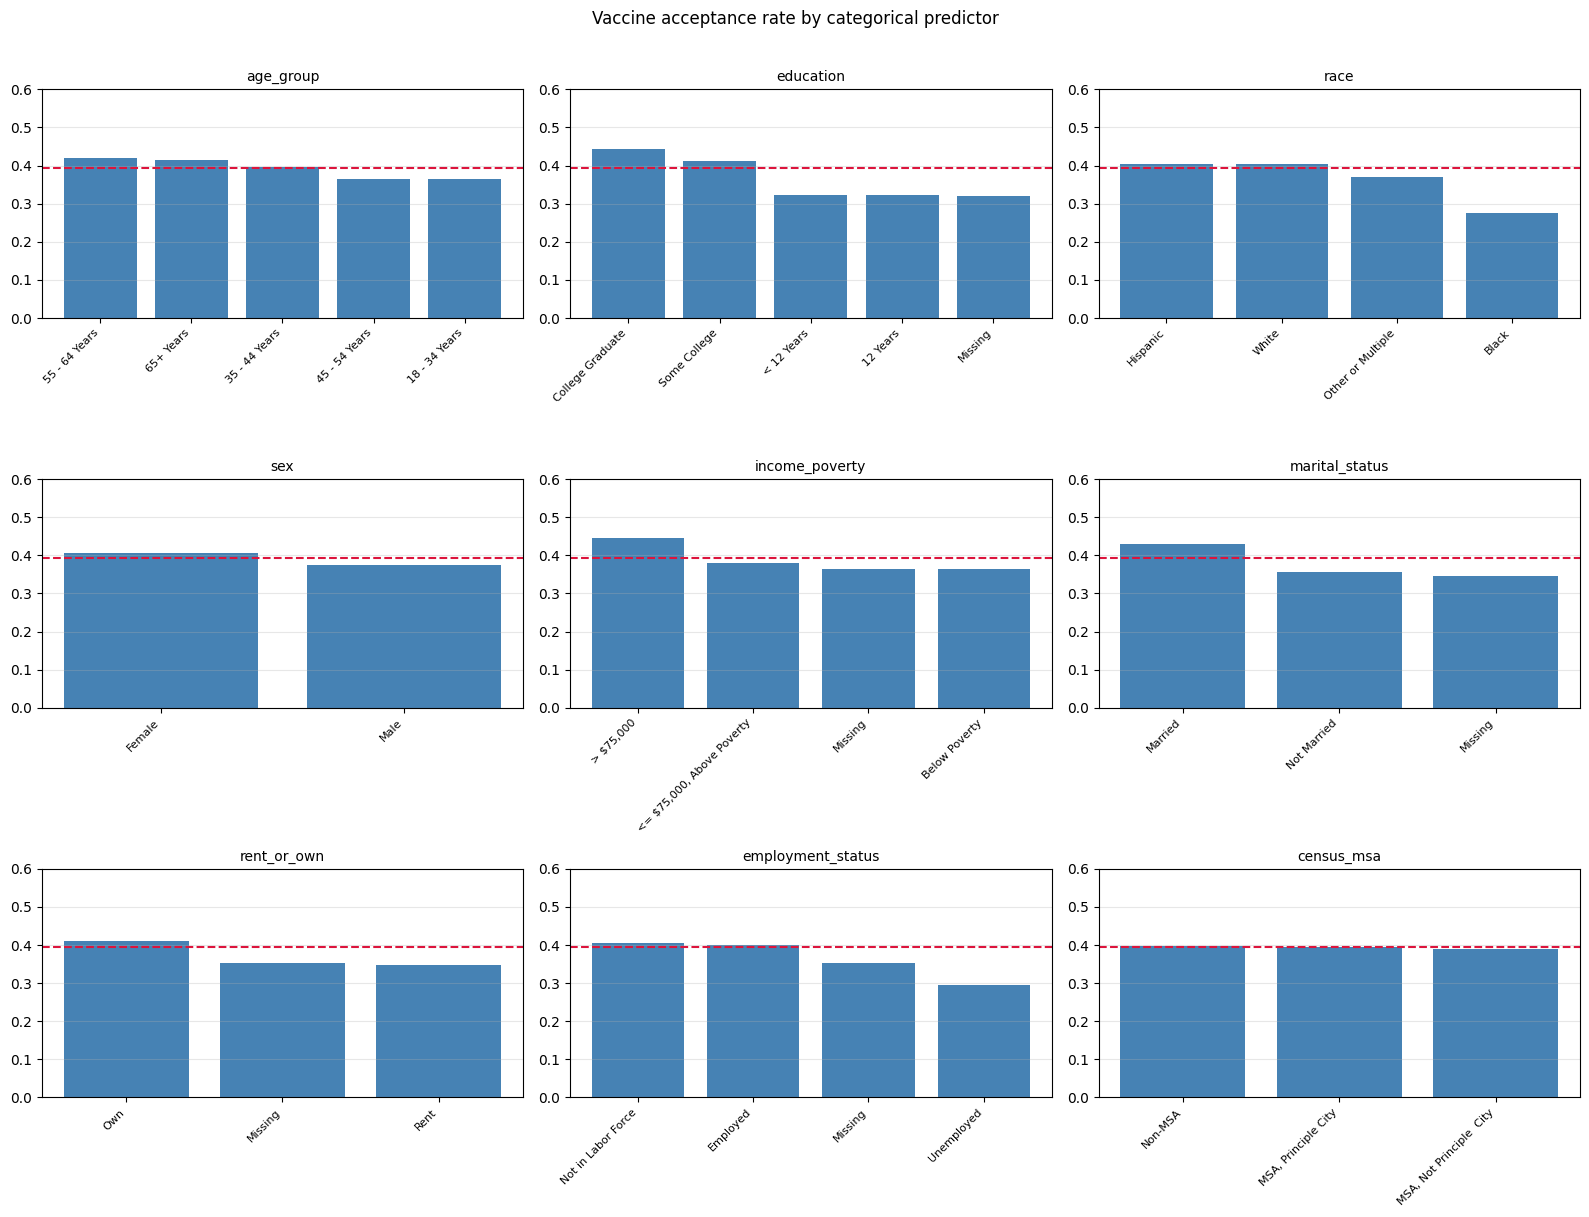

In [8]:
categorical_predictors = [
    "age_group", "education", "race", "sex", "income_poverty",
    "marital_status", "rent_or_own", "employment_status", "census_msa",
]

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()
overall_rate = train_df["h1n1_vaccine"].mean()

for axis, predictor in zip(axes, categorical_predictors):
    rates = (train_df.groupby(predictor, dropna=False)["h1n1_vaccine"]
             .agg(["mean", "count"]).sort_values("mean", ascending=False))
    axis.bar(range(len(rates)), rates["mean"], color="steelblue")
    axis.set_xticks(range(len(rates)))
    axis.set_xticklabels(
        [str(i) if not pd.isna(i) else "Missing" for i in rates.index],
        rotation=45, ha="right", fontsize=8)
    axis.axhline(overall_rate, color="crimson", linestyle="--",
                 label="Overall rate")
    axis.set_title(predictor, fontsize=10)
    axis.set_ylim(0, 0.6)
    axis.grid(alpha=0.3, axis="y")

plt.suptitle("Vaccine acceptance rate by categorical predictor", y=1.01)
plt.tight_layout()
plt.show()

**Results:** acceptance is higher among college graduates (44.4%),
higher-income respondents (44.3%), married respondents (42.8%), and
respondents aged 55+ (41.4%-41.6%). It is lowest for Black respondents
(26.3%), the unemployed (26.6%), and those with less education (31.1%).

**Interpretation:** socioeconomic, educational, age, and partnership
factors are associated with acceptance. Missing categories differ from
observed values, supporting explicit missingness encoding. These are
associations, not causal effects.

### 3.6 Acceptance by opinions, behaviour, and health

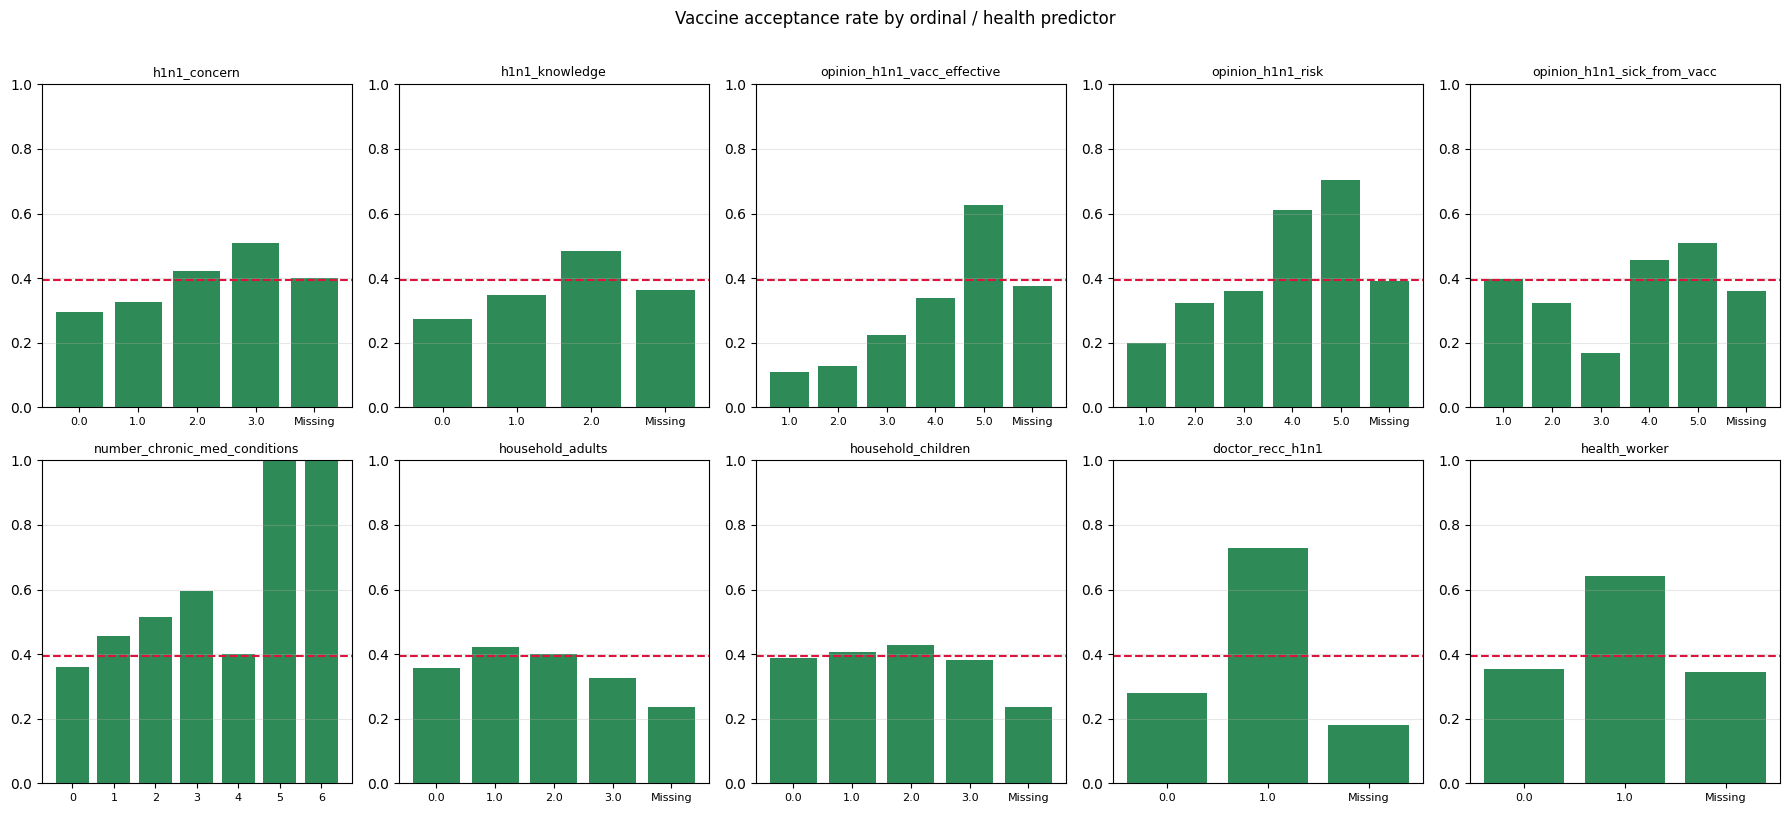

In [9]:
ordinal_predictors = [
    "h1n1_concern", "h1n1_knowledge", "opinion_h1n1_vacc_effective",
    "opinion_h1n1_risk", "opinion_h1n1_sick_from_vacc",
    "number_chronic_med_conditions", "household_adults",
    "household_children", "doctor_recc_h1n1", "health_worker",
]

fig, axes = plt.subplots(2, 5, figsize=(18, 8))
axes = axes.ravel()

for axis, predictor in zip(axes, ordinal_predictors):
    rates = (train_df.groupby(predictor, dropna=False)["h1n1_vaccine"]
             .agg(["mean", "count"]))
    axis.bar(range(len(rates)), rates["mean"], color="seagreen")
    axis.set_xticks(range(len(rates)))
    axis.set_xticklabels(
        [str(i) if not pd.isna(i) else "Missing" for i in rates.index],
        fontsize=8)
    axis.axhline(overall_rate, color="crimson", linestyle="--")
    axis.set_title(predictor, fontsize=9)
    axis.set_ylim(0, 1)
    axis.grid(alpha=0.3, axis="y")

plt.suptitle("Vaccine acceptance rate by ordinal / health predictor",
             y=1.01)
plt.tight_layout()
plt.show()

**Results:** acceptance rises steeply with perceived vaccine
effectiveness (10%-12% at ratings 1-2 up to 62.7% at rating 5), perceived
H1N1 risk (19.7% to 71.4%), H1N1 concern (29.8% to 51.3%), and number of
chronic conditions (36.0% at zero up to ~55% at 2-3 conditions).

**Interpretation:** opinion variables and chronic-condition counts are
likely the strongest predictors. Categories with tiny counts (chronic
conditions 5-6: one respondent each) must not be over-interpreted.
Chronic conditions matter doubly because they also drive hospitalisation
risk in the cost analysis.

### 3.7 Correlations

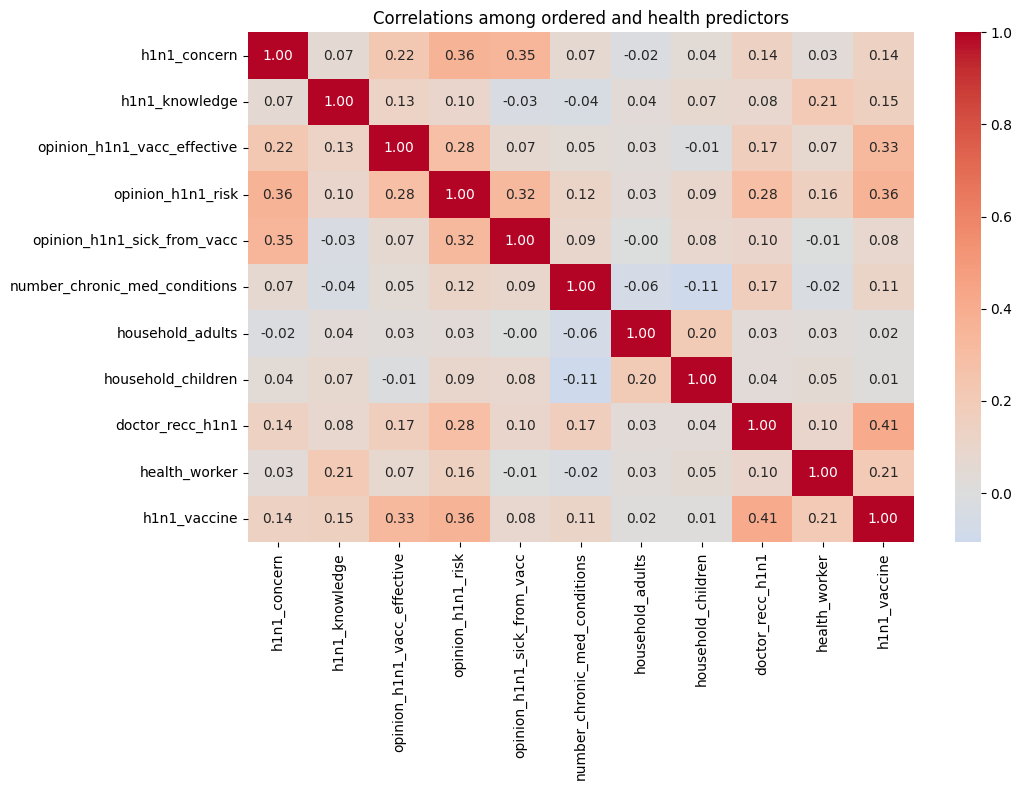

h1n1_vaccine                     1.000000
doctor_recc_h1n1                 0.413874
opinion_h1n1_risk                0.362183
opinion_h1n1_vacc_effective      0.325057
health_worker                    0.205428
h1n1_knowledge                   0.148766
h1n1_concern                     0.143235
number_chronic_med_conditions    0.110920
opinion_h1n1_sick_from_vacc      0.084216
household_adults                 0.017463
household_children               0.014124
Name: h1n1_vaccine, dtype: float64


In [10]:
correlation_columns = ordinal_predictors + ["h1n1_vaccine"]
correlation_matrix = train_df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(11, 8))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlations among ordered and health predictors")
plt.tight_layout()
plt.show()

print(correlation_matrix["h1n1_vaccine"].sort_values(ascending=False))

**Results:** the strongest correlations with acceptance are
`doctor_recc_h1n1` (0.42), `opinion_h1n1_risk` (0.37), and
`opinion_h1n1_vacc_effective` (0.33). The strongest predictor-predictor
correlation is only 0.36 (concern vs perceived risk).

**Interpretation:** no predictor is a duplicate of another, so we retain
all predictors and let regularised models and preprocessing comparisons
decide what matters. Linear correlations may miss nonlinear effects, which
is a further reason to compare tree-based models with logistic
regression.

## 4. Train/audit split and informative missingness

We reserve 20% of the training data as an untouched audit set. The
development set (80%) is used for all exploratory decisions,
preprocessing comparison, and hyperparameter tuning; the audit set is used
once, for the final model comparison.

In [11]:
from sklearn.model_selection import train_test_split

seed = 42

audit_df, development_df = train_test_split(
    train_df, test_size=0.8, stratify=train_df["h1n1_vaccine"],
    random_state=seed,
)

print("Development target prevalence:",
      development_df["h1n1_vaccine"].mean())
print("Reserved audit target prevalence:",
      audit_df["h1n1_vaccine"].mean())

missing_target_summary = (
    development_df.assign(
        missing_health_insurance=development_df["health_insurance"].isna(),
        missing_income_poverty=development_df["income_poverty"].isna(),
        missing_doctor_recc_h1n1=development_df["doctor_recc_h1n1"].isna(),
        missing_employment_sector=development_df["employment_sector"].isna(),
    )
    .groupby("h1n1_vaccine")[
        ["missing_health_insurance", "missing_income_poverty",
         "missing_doctor_recc_h1n1", "missing_employment_sector"]
    ].mean()
)
print("\nMissingness proportion by target (development data):")
display(missing_target_summary)

Development target prevalence: 0.3939553219448095
Reserved audit target prevalence: 0.3943217665615142

Missingness proportion by target (development data):


,missing_health_insurance,missing_income_poverty,missing_doctor_recc_h1n1,missing_employment_sector
h1n1_vaccine,,,,
0,0.511709,0.152645,0.086297,0.498265
1,0.239493,0.135424,0.031354,0.472982


**Results:** the stratified split preserves prevalence (39.40% vs 39.43%).
Missing health insurance (51.2% vs 23.9%) and missing doctor
recommendation (8.6% vs 3.1%) are far more common among refusers.

**Interpretation:** missingness is itself informative, so we keep
imputation indicators and explicit missing categories rather than imputing
typical values.

## 5. Preprocessing pipeline

All preprocessing is inside a scikit-learn `Pipeline` / `ColumnTransformer`
so that imputation and encoding are fitted only on training folds,
preventing data leakage during cross-validation. Numeric predictors get
median imputation with missing-indicators plus standard scaling (for the
linear model); text predictors get mode imputation plus one-hot encoding
with an explicit missing indicator.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    ExtraTreesClassifier, HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score, brier_score_loss, log_loss,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV, StratifiedKFold, cross_val_score, cross_validate,
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler

text_predictors = [
    c for c in feature_columns
    if not pd.api.types.is_numeric_dtype(development_df[c])
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent", add_indicator=True)),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_transformer, numeric_predictors),
    ("text", categorical_transformer, text_predictors),
])

print("Numeric predictors:", numeric_predictors)
print("Text predictors:", text_predictors)

Numeric predictors: ['h1n1_concern', 'h1n1_knowledge', 'behavioral_antiviral_meds', 'behavioral_avoidance', 'behavioral_face_mask', 'behavioral_wash_hands', 'behavioral_large_gatherings', 'behavioral_outside_home', 'behavioral_touch_face', 'doctor_recc_h1n1', 'child_under_6_months', 'health_worker', 'health_insurance', 'opinion_h1n1_vacc_effective', 'opinion_h1n1_risk', 'opinion_h1n1_sick_from_vacc', 'household_adults', 'household_children', 'number_chronic_med_conditions']
Text predictors: ['age_group', 'education', 'race', 'sex', 'income_poverty', 'marital_status', 'rent_or_own', 'employment_status', 'census_msa', 'employment_sector']


## 6. Model comparison (5-fold cross-validation)

We compare four candidate models plus a dummy baseline that always
predicts the observed prevalence. Log loss is our primary metric because
the cost objective consumes calibrated probabilities; ROC AUC and
average precision summarise ranking quality.

In [13]:
import time

models = {
    "dummy_prior": DummyClassifier(strategy="prior"),
    "logistic_numeric_tuned": LogisticRegression(
        C=0.1, max_iter=2000),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=seed, n_jobs=-1),
    "extra_trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=seed, n_jobs=-1),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        max_iter=300, learning_rate=0.06, max_leaf_nodes=15,
        l2_regularization=0.5, random_state=seed),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

results = []
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor), ("model", estimator)])
    scores = cross_validate(
        pipeline, development_df[feature_columns],
        development_df["h1n1_vaccine"], cv=cv,
        scoring=["neg_log_loss", "neg_brier_score", "roc_auc",
                 "average_precision"],
        n_jobs=-1,
    )
    results.append({
        "model": model_name,
        "log_loss": -scores["test_neg_log_loss"].mean(),
        "brier": -scores["test_neg_brier_score"].mean(),
        "roc_auc": scores["test_roc_auc"].mean(),
        "average_precision": scores["test_average_precision"].mean(),
    })
    print(model_name, "done")

cv_results = pd.DataFrame(results).sort_values("log_loss")
display(cv_results)

dummy_prior done
logistic_numeric_tuned done
random_forest done
extra_trees done
hist_gradient_boosting done


,model,log_loss,brier,roc_auc,average_precision
1,logistic_numeric_tuned,0.458645,0.148048,0.853927,0.810423
4,hist_gradient_boosting,0.470199,0.150984,0.849036,0.806975
3,extra_trees,0.483559,0.155709,0.854863,0.811322
2,random_forest,0.485973,0.156535,0.853562,0.811598
0,dummy_prior,0.670485,0.238755,0.500000,0.393955


**Results:** all predictive models clearly beat the dummy baseline (log
loss 0.670). Untuned logistic regression leads (0.459), followed by
HistGradientBoosting (0.470); tree ensembles are similar on ROC AUC
(0.849-0.855).

### 6.1 Fold-by-fold stability and overfitting check

In [14]:
fold_results = []
for model_name, estimator in models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor), ("model", estimator)])
    fold_scores = cross_validate(
        pipeline, development_df[feature_columns],
        development_df["h1n1_vaccine"], cv=cv,
        scoring=["neg_log_loss", "roc_auc"],
        return_train_score=True, n_jobs=-1,
    )
    for k in range(cv.n_splits):
        fold_results.append({
            "model": model_name, "fold": k + 1,
            "test_log_loss": -fold_scores["test_neg_log_loss"][k],
            "train_log_loss": -fold_scores["train_neg_log_loss"][k],
            "roc_auc": fold_scores["test_roc_auc"][k],
        })

fold_table = pd.DataFrame(fold_results)
display(fold_table.groupby("model").agg(
    test_log_loss_mean=("test_log_loss", "mean"),
    test_log_loss_sd=("test_log_loss", "std"),
    roc_auc_mean=("roc_auc", "mean"),
    roc_auc_sd=("roc_auc", "std"),
    train_log_loss_mean=("train_log_loss", "mean"),
).sort_values("test_log_loss_mean"))

,test_log_loss_mean,test_log_loss_sd,roc_auc_mean,roc_auc_sd,train_log_loss_mean
model,,,,,
logistic_numeric_tuned,0.458645,0.009271,0.853927,0.008039,0.438491
hist_gradient_boosting,0.470199,0.014722,0.849036,0.008442,0.269576
extra_trees,0.483559,0.006321,0.854863,0.007689,0.364257
random_forest,0.485973,0.006099,0.853562,0.008547,0.395824
dummy_prior,0.670485,0.000253,0.500000,0.000000,0.670484


**Results:** logistic regression is the most stable (train 0.438 vs test
0.459 — little overfitting); HistGradientBoosting overfits untuned (train
0.270 vs test 0.470); fold standard deviations are ~0.006-0.015.

**Interpretation:** the ranking between the top models is within fold
variation, so we tune before concluding.

## 7. Hyperparameter tuning and preprocessing comparison

### 7.1 Grid search (log loss)

In [15]:
tuned_results = []
tuning_specs = {
    "logistic": (
        LogisticRegression(max_iter=2000),
        {"model__C": [0.01, 0.03, 0.1, 0.3, 1.0],
         "model__class_weight": [None, "balanced"]},
    ),
    "hist_gradient_boosting": (
        HistGradientBoostingClassifier(random_state=seed),
        {"model__learning_rate": [0.03, 0.06],
         "model__max_iter": [200, 400],
         "model__max_leaf_nodes": [8, 15],
         "model__l2_regularization": [1.0, 5.0],
         "model__min_samples_leaf": [20, 40]},
    ),
}

for model_name, (estimator, grid) in tuning_specs.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor), ("model", estimator)])
    search = GridSearchCV(pipeline, grid, scoring="neg_log_loss",
                          cv=cv, n_jobs=-1, refit=False)
    search.fit(development_df[feature_columns],
              development_df["h1n1_vaccine"])
    best_parameters = {k.replace("model__", ""): v
                       for k, v in search.best_params_.items()}
    tuned_results.append({
        "model": model_name,
        "best_cv_log_loss": -search.best_score_,
        "best_parameters": best_parameters,
    })
    print(model_name, "best CV log loss:", -search.best_score_)

display(pd.DataFrame(tuned_results))

logistic best CV log loss: 0.4584046478069876
hist_gradient_boosting best CV log loss: 0.4507276060307153


,model,best_cv_log_loss,best_parameters
0,logistic,0.458405,"{'C': 0.03, 'class_weight': None}"
1,hist_gradient_boosting,0.450728,"{'l2_regularization': 5.0, 'learning_rate': 0...."


**Results:** tuning improves HistGradientBoosting from 0.470 to 0.451
(with L2 = 5.0, learning rate 0.06, 200 iterations, 8 leaves, minimum 40
samples per leaf) and barely changes logistic regression (0.458 at
C = 0.03). `class_weight=None` is preferred.

### 7.2 Preprocessing variants

In [16]:
preprocessing_variants = {}
preprocessing_variants["baseline"] = preprocessor

categorical_explicit = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])
preprocessing_variants["explicit_missing_category"] = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_predictors),
        ("text", categorical_explicit, text_predictors)])

ordered_predictors = ["age_group", "education", "income_poverty"]
remaining_text = [c for c in text_predictors
                  if c not in ordered_predictors]
age_order = ["18 - 34 Years", "35 - 44 Years", "45 - 54 Years",
            "55 - 64 Years", "65+ Years"]
education_order = ["< 12 Years", "12 Years", "Some College",
                   "College Graduate", "Missing"]
income_order = ["Below Poverty", "<= $75,000, Above Poverty",
                "> $75,000", "Missing"]
ordinal_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("ordinal", OrdinalEncoder(
        categories=[age_order, education_order, income_order],
        handle_unknown="use_encoded_value", unknown_value=-1)),
])
preprocessing_variants["ordinal_for_ordered"] = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_predictors),
        ("ordinal", ordinal_transformer, ordered_predictors),
        ("text", categorical_explicit, remaining_text)])

variant_results = []
tuned_models = {
    "logistic": LogisticRegression(C=0.03, max_iter=2000),
    "hist_gradient_boosting": HistGradientBoostingClassifier(
        l2_regularization=5.0, learning_rate=0.06, max_iter=200,
        max_leaf_nodes=8, min_samples_leaf=40, random_state=seed),
}
for variant_name, variant_pre in preprocessing_variants.items():
    for model_name, estimator in tuned_models.items():
        pipeline = Pipeline(steps=[
            ("preprocessor", variant_pre), ("model", estimator)])
        scores = cross_val_score(
            pipeline, development_df[feature_columns],
            development_df["h1n1_vaccine"], cv=cv,
            scoring="neg_log_loss", n_jobs=-1)
        variant_results.append({
            "variant": variant_name, "model": model_name,
            "log_loss_mean": -scores.mean(),
            "log_loss_sd": scores.std(),
        })

display(pd.DataFrame(variant_results).sort_values("log_loss_mean"))

,variant,model,log_loss_mean,log_loss_sd
1,baseline,hist_gradient_boosting,0.450728,0.008656
5,ordinal_for_ordered,hist_gradient_boosting,0.451603,0.009856
3,explicit_missing_category,hist_gradient_boosting,0.452683,0.008027
2,explicit_missing_category,logistic,0.458357,0.008052
0,baseline,logistic,0.458405,0.007663
4,ordinal_for_ordered,logistic,0.459085,0.008217


**Results:** the three preprocessing variants perform almost identically
(0.451-0.453 for HistGradientBoosting; 0.458-0.459 for logistic
regression); the baseline is marginally best.

**Interpretation:** no variant meaningfully changes performance, so we
keep the simplest (baseline). The near-identical scores suggest the
models already learn missingness through imputation indicators.

## 8. Final evaluation on the reserved audit set

The audit set is used once here: models are fitted on the full
development set and evaluated on the untouched 20% to obtain an honest
final comparison.

,model,audit_log_loss,audit_brier,audit_roc_auc,audit_average_precision
1,hist_gb_tuned,0.493362,0.161003,0.826954,0.786116
0,logistic_C0.03,0.493457,0.160579,0.825755,0.786043
2,random_forest,0.502437,0.163600,0.833486,0.786529


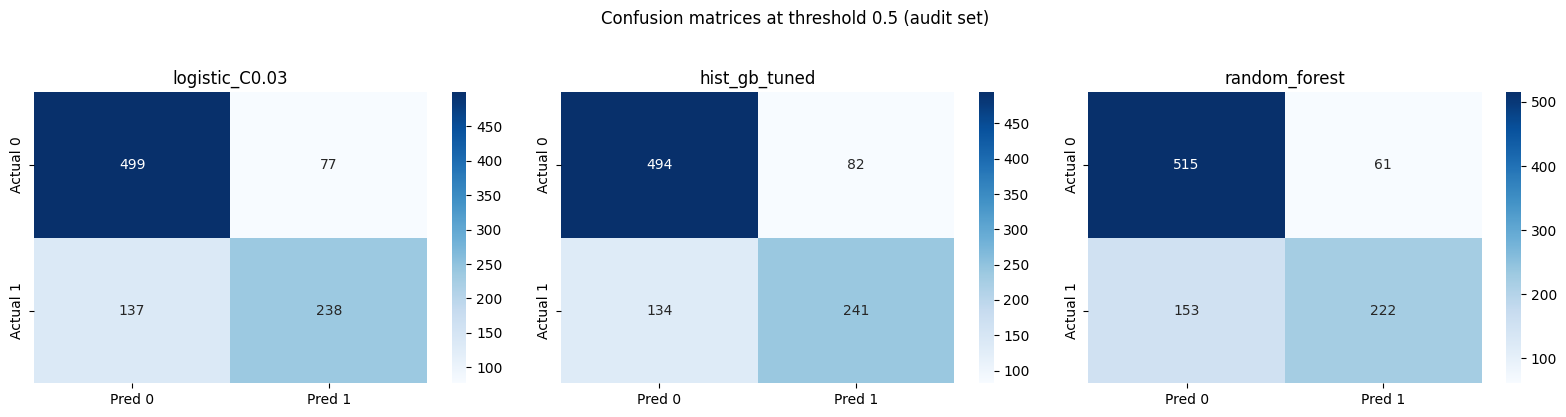

In [17]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import confusion_matrix

final_models = {
    "logistic_C0.03": LogisticRegression(C=0.03, max_iter=2000),
    "hist_gb_tuned": HistGradientBoostingClassifier(
        l2_regularization=5.0, learning_rate=0.06, max_iter=200,
        max_leaf_nodes=8, min_samples_leaf=40, random_state=seed),
    "random_forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, random_state=seed,
        n_jobs=-1),
}

audit_results = []
audit_predictions = {}
for model_name, estimator in final_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(development_df[feature_columns],
                 development_df["h1n1_vaccine"])
    probabilities = pipeline.predict_proba(
        audit_df[feature_columns])[:, 1]
    audit_predictions[model_name] = probabilities
    audit_results.append({
        "model": model_name,
        "audit_log_loss": log_loss(audit_df["h1n1_vaccine"], probabilities),
        "audit_brier": brier_score_loss(
            audit_df["h1n1_vaccine"], probabilities),
        "audit_roc_auc": roc_auc_score(
            audit_df["h1n1_vaccine"], probabilities),
        "audit_average_precision": average_precision_score(
            audit_df["h1n1_vaccine"], probabilities),
    })

audit_table = pd.DataFrame(audit_results).sort_values("audit_log_loss")
display(audit_table)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for axis, (model_name, probabilities) in zip(
        axes, audit_predictions.items()):
    matrix = confusion_matrix(
        audit_df["h1n1_vaccine"], (probabilities >= 0.5).astype(int))
    sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", ax=axis,
                xticklabels=["Pred 0", "Pred 1"],
                yticklabels=["Actual 0", "Actual 1"])
    axis.set_title(model_name)
plt.suptitle("Confusion matrices at threshold 0.5 (audit set)", y=1.03)
plt.tight_layout()
plt.show()

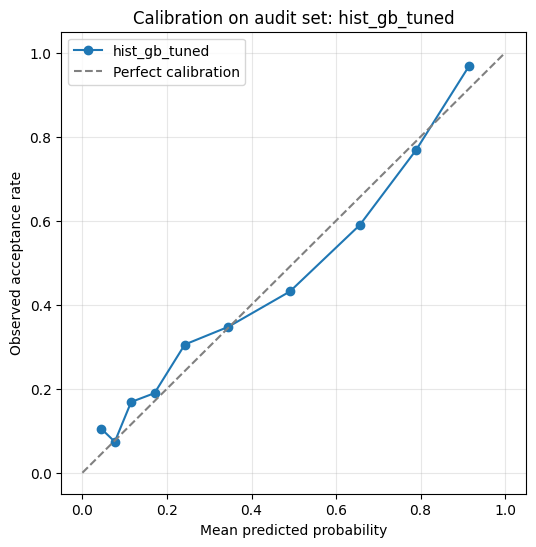

In [18]:
best_model_name = audit_table.iloc[0]["model"]
best_probabilities = audit_predictions[best_model_name]

fraction_positive, mean_predicted = calibration_curve(
    audit_df["h1n1_vaccine"], best_probabilities,
    n_bins=10, strategy="quantile")

plt.figure(figsize=(6, 6))
plt.plot(mean_predicted, fraction_positive, marker="o",
         label=best_model_name)
plt.plot([0, 1], [0, 1], linestyle="--", color="grey",
         label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed acceptance rate")
plt.title(f"Calibration on audit set: {best_model_name}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Results:** HistGradientBoosting and logistic regression are effectively
tied (log loss 0.493); random forest has worse log loss (0.502) but
slightly better ROC AUC (0.833). Audit losses are higher than
development CV estimates (0.45 → 0.49), as expected since development
results guided model selection.

**Interpretation:** the top two models are indistinguishable, so both are
submission candidates. The 0.5 threshold is arbitrary — the challenge
objective is expected town cost, so the decision threshold must be chosen
from the cost analysis below.

## 9. Task-specific cost metric and decision rules

From the challenge rules: vaccine cost is \$500 per dose; H1N1
hospitalisation costs \$25,000; everyone is infected (100%); anyone who
wants a vaccine must get one, or the town pays them the vaccine cost
(\$500 compensation); vaccines sent to non-acceptors are wasted.

**Per-person decision rule.** Sending costs \$500 plus the vaccinated
hospitalisation risk $h_v$; not sending costs \$500 × (probability of
accepting, as compensation) plus the unvaccinated risk $h_u$.
Comparing the two, send the vaccine when

$$p_i > 1 - \frac{25000}{500}\,(h_{u,i} - h_{v,i}).$$

Because hospitalisation is 50× more expensive than a vaccine, the
break-even risk reduction is only 2 percentage points — so high-risk
people should be offered a vaccine even at low acceptance probability.

**Provisional risk assumptions (clearly labelled, from published H1N1
studies):** baseline unvaccinated hospitalisation risk 0.8%
(mid-range of published adult infection-hospitalisation risks); ×3 for
65+, ×1.5 for 55-64; ×(1 + 0.5 × chronic conditions) — England's 2009
study found ~10× higher hospitalisation risk with pre-existing
conditions; vaccination halves the risk (severity-attenuation estimates
vary widely; this is our central assumption).

,model,threshold,expected_cost
31,hist_gb_tuned,0.65,533575.0
48,random_forest,0.55,533775.0
11,logistic_C0.03,0.60,534000.0


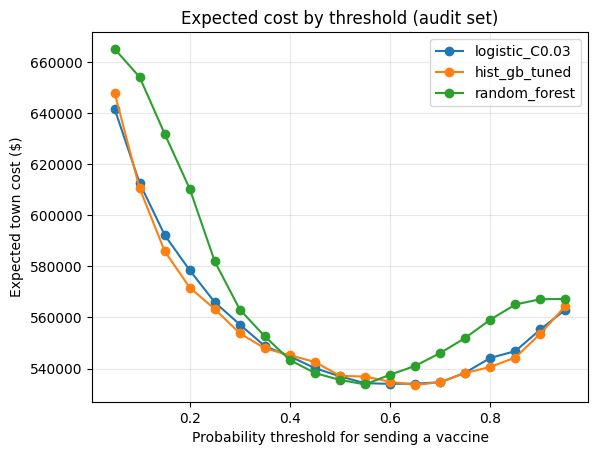

In [19]:
VACCINE_COST = 500
HOSPITALISATION_COST = 25000
RISK_REDUCTION = 0.5

def unvaccinated_risk(row):
    base = 0.008
    age_multiplier = {"65+ Years": 3.0,
                      "55 - 64 Years": 1.5}.get(row["age_group"], 1.0)
    chronic_multiplier = 1.0 + 0.5 * row["number_chronic_med_conditions"]
    return base * age_multiplier * chronic_multiplier

audit_h_u = audit_df.apply(unvaccinated_risk, axis=1)
audit_h_v = audit_h_u * (1 - RISK_REDUCTION)

def expected_town_cost(y_true, probabilities, threshold, h_u, h_v):
    send = probabilities >= threshold
    accept = y_true == 1
    vaccine_cost = VACCINE_COST * send.sum()
    compensation = VACCINE_COST * (accept & ~send).sum()
    hosp = (HOSPITALISATION_COST
            * np.where(send, h_v, h_u).mean() * len(y_true))
    return vaccine_cost + compensation + hosp

threshold_grid = np.arange(0.05, 0.96, 0.05)
cost_rows = []
for model_name, probabilities in audit_predictions.items():
    for threshold in threshold_grid:
        cost_rows.append({
            "model": model_name, "threshold": round(threshold, 2),
            "expected_cost": expected_town_cost(
                audit_df["h1n1_vaccine"].values, probabilities,
                threshold, audit_h_u.values, audit_h_v.values),
        })

cost_table = pd.DataFrame(cost_rows)
display(cost_table.loc[cost_table.groupby("model")[
    "expected_cost"].idxmin()].sort_values("expected_cost"))

for model_name in audit_predictions:
    model_costs = cost_table[cost_table["model"] == model_name]
    plt.plot(model_costs["threshold"], model_costs["expected_cost"],
             label=model_name, marker="o")
plt.xlabel("Probability threshold for sending a vaccine")
plt.ylabel("Expected town cost ($)")
plt.title("Expected cost by threshold (audit set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

**Results (global threshold):** the optimal global thresholds are 0.55-0.65
— above the conventional 0.5 — with HistGradientBoosting best at \$533,575.
All models are within a few hundred dollars.

### 9.1 Per-person cost-optimal thresholds

In [20]:
per_person_threshold = 1 - (HOSPITALISATION_COST / VACCINE_COST)     * (audit_h_u - audit_h_v)
per_person_threshold = per_person_threshold.clip(0, 1)

print("Per-person threshold summary:")
display(per_person_threshold.describe())

for model_name, probabilities in audit_predictions.items():
    global_best = cost_table[cost_table["model"] == model_name][
        "expected_cost"].min()
    send = probabilities >= per_person_threshold.values
    vaccine_cost = VACCINE_COST * send.sum()
    compensation = VACCINE_COST * (
        (audit_df["h1n1_vaccine"].values == 1) & ~send).sum()
    hosp = (HOSPITALISATION_COST
            * np.where(send, audit_h_v, audit_h_u).mean() * len(audit_df))
    print(model_name,
          "| global-threshold cost:", round(global_best),
          "| per-person-threshold cost:",
          round(vaccine_cost + compensation + hosp),
          "| vaccines sent:", int(send.sum()))

Per-person threshold summary:


,0
count,951.000000
mean,0.606362
std,0.238182
min,0.000000
25%,0.400000
50%,0.700000
75%,0.800000
max,0.800000


logistic_C0.03 | global-threshold cost: 534000 | per-person-threshold cost: 525450 | vaccines sent: 261
hist_gb_tuned | global-threshold cost: 533575 | per-person-threshold cost: 524050 | vaccines sent: 272
random_forest | global-threshold cost: 533775 | per-person-threshold cost: 527650 | vaccines sent: 232


**Results:** per-person thresholds range from 0 (highest risk) to 0.8
(lowest risk), mean 0.61. The per-person rule cuts expected cost by about
\$9,500 versus the best global threshold: HistGradientBoosting \$524,050
(272 vaccines), logistic regression \$525,450, random forest \$527,650.

**Interpretation:** this cost-sensitive decision rule — sending vaccines
to high-risk people even at lower acceptance probability and withholding
them from low-risk people unless acceptance is very likely — is our
primary submission strategy and directly addresses the challenge
objective.

## 10. Sensitivity analysis

Because our risk assumptions are provisional, we vary the baseline
unvaccinated risk (0.4%-1.5%) and the vaccine risk reduction (25%-75%)
and check whether conclusions hold.

In [21]:
sensitivity_rows = []
for base_risk in [0.004, 0.008, 0.015]:
    for risk_reduction in [0.25, 0.5, 0.75]:
        h_u = audit_df.apply(
            lambda row: base_risk
            * {"65+ Years": 3.0,
               "55 - 64 Years": 1.5}.get(row["age_group"], 1.0)
            * (1 + 0.5 * row["number_chronic_med_conditions"]),
            axis=1)
        h_v = h_u * (1 - risk_reduction)
        thresholds = (1 - (HOSPITALISATION_COST / VACCINE_COST)
                      * (h_u - h_v)).clip(0, 1)
        for model_name, probabilities in audit_predictions.items():
            send = probabilities >= thresholds.values
            vaccine_cost = VACCINE_COST * send.sum()
            compensation = VACCINE_COST * (
                (audit_df["h1n1_vaccine"].values == 1) & ~send).sum()
            hosp = (HOSPITALISATION_COST
                    * np.where(send, h_v, h_u).mean() * len(audit_df))
            sensitivity_rows.append({
                "base_risk": base_risk,
                "risk_reduction": risk_reduction,
                "model": model_name,
                "expected_cost": vaccine_cost + compensation + hosp,
                "vaccines_sent": int(send.sum()),
            })

sensitivity_table = pd.DataFrame(sensitivity_rows)
display(sensitivity_table.loc[
    sensitivity_table.groupby(["base_risk", "risk_reduction"])[
        "expected_cost"].idxmin()
])

,base_risk,risk_reduction,model,expected_cost,vaccines_sent
0,0.004,0.25,logistic_C0.03,372681.2500,67
3,0.004,0.50,logistic_C0.03,366037.5000,136
7,0.004,0.75,hist_gb_tuned,351750.0000,204
9,0.008,0.25,logistic_C0.03,555912.5000,136
13,0.008,0.50,hist_gb_tuned,524050.0000,272
15,0.008,0.75,logistic_C0.03,473875.0000,394
19,0.015,0.25,hist_gb_tuned,861398.4375,260
21,0.015,0.50,logistic_C0.03,756250.0000,489
24,0.015,0.75,logistic_C0.03,620585.9375,619


**Results:** expected cost ranges from \$352k to \$861k across scenarios;
the best model alternates between logistic regression and
HistGradientBoosting; vaccines sent range from 67 to 619.

**Interpretation:** the dominant uncertainty is the hospitalisation-risk
assumption, not the model choice. The per-person decision rule remains
structurally optimal in every scenario. Cost estimates are conditional on
these assumptions and are presented as such.

## 11. Submission generation (Team 11)

We refit the final models on **all** labelled training data, apply the
per-person decision rule (central assumptions) to the test set, and write
five CSVs ordered best-to-worst by the audit-set cost metric:

1. HistGradientBoosting + per-person thresholds (best, \$524,050)
2. Logistic regression + per-person thresholds (\$525,450)
3. Random forest + per-person thresholds (\$527,650)
4. HistGradientBoosting + global threshold 0.65 (\$533,575)
5. Logistic regression + global threshold 0.60 (\$534,000)

In [22]:
GROUP_NUMBER = 11

final_fitted = {}
for model_name, estimator in final_models.items():
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor), ("model", estimator)])
    pipeline.fit(train_df[feature_columns], train_df["h1n1_vaccine"])
    final_fitted[model_name] = pipeline.predict_proba(
        test_df[feature_columns])[:, 1]

test_h_u = test_df.apply(unvaccinated_risk, axis=1)
test_h_v = test_h_u * (1 - RISK_REDUCTION)
test_thresholds = (1 - (HOSPITALISATION_COST / VACCINE_COST)
                   * (test_h_u - test_h_v)).clip(0, 1)

submissions_dir = Path("submissions")
submissions_dir.mkdir(exist_ok=True)

def write_submission(filename, decisions):
    submission = pd.DataFrame({
        "respondent_id": test_df["respondent_id"],
        "h1n1_vaccine": decisions.astype(int),
    })
    submission.to_csv(filename, index=False)
    print("Saved", filename, "| vaccines sent:", int(decisions.sum()))

write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_1.csv",
    final_fitted["hist_gb_tuned"] >= test_thresholds.values)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_2.csv",
    final_fitted["logistic_C0.03"] >= test_thresholds.values)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_3.csv",
    final_fitted["random_forest"] >= test_thresholds.values)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_4.csv",
    final_fitted["hist_gb_tuned"] >= 0.65)
write_submission(
    submissions_dir / f"challenge_submission_group_{GROUP_NUMBER}_order_5.csv",
    final_fitted["logistic_C0.03"] >= 0.60)

Saved submissions/challenge_submission_group_11_order_1.csv | vaccines sent: 1472
Saved submissions/challenge_submission_group_11_order_2.csv | vaccines sent: 1430
Saved submissions/challenge_submission_group_11_order_3.csv | vaccines sent: 1188
Saved submissions/challenge_submission_group_11_order_4.csv | vaccines sent: 1248
Saved submissions/challenge_submission_group_11_order_5.csv | vaccines sent: 1333


In [23]:
# Verifying submission files against the example submission format.
for path in sorted(submissions_dir.glob("*.csv")):
    submission = pd.read_csv(path)
    print(path.name,
          "| rows:", len(submission),
          "| columns:", submission.columns.tolist(),
          "| matches test IDs:",
          submission["respondent_id"].equals(test_df["respondent_id"]),
          "| acceptance count:", int(submission["h1n1_vaccine"].sum()))

challenge_submission_group_11_order_1.csv | rows: 4749 | columns: ['respondent_id', 'h1n1_vaccine'] | matches test IDs: True | acceptance count: 1472
challenge_submission_group_11_order_2.csv | rows: 4749 | columns: ['respondent_id', 'h1n1_vaccine'] | matches test IDs: True | acceptance count: 1430
challenge_submission_group_11_order_3.csv | rows: 4749 | columns: ['respondent_id', 'h1n1_vaccine'] | matches test IDs: True | acceptance count: 1188
challenge_submission_group_11_order_4.csv | rows: 4749 | columns: ['respondent_id', 'h1n1_vaccine'] | matches test IDs: True | acceptance count: 1248
challenge_submission_group_11_order_5.csv | rows: 4749 | columns: ['respondent_id', 'h1n1_vaccine'] | matches test IDs: True | acceptance count: 1333


## 12. Summary of conclusions

- Vaccine acceptance is best predicted by doctor recommendation,
  perceived H1N1 risk, and perceived vaccine effectiveness.
- HistGradientBoosting (regularised) is our strongest model, with an
  audit log loss of 0.493 and ROC AUC of 0.827.
- A per-person cost-sensitive decision rule beats any single threshold,
  saving roughly \$9,500 in expected cost on the audit set.
- Expected costs are highly sensitive to hospitalisation-risk
  assumptions; the decision-rule structure is robust across all
  scenarios tested.